In [1]:
import pandas as pd
import seaborn as sns

# Cargar datos
ad_data = pd.read_csv('../datasets/advertising.xls')

# Vistazo rápido
print(ad_data.head())

   Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  \
0                     68.95   35     61833.90                256.09   
1                     80.23   31     68441.85                193.77   
2                     69.47   26     59785.94                236.50   
3                     74.15   29     54806.18                245.89   
4                     68.37   35     73889.99                225.58   

                           Ad Topic Line            City  Male     Country  \
0     Cloned 5thgeneration orchestration     Wrightburgh     0     Tunisia   
1     Monitored national standardization       West Jodi     1       Nauru   
2       Organic bottom-line service-desk        Davidton     0  San Marino   
3  Triple-buffered reciprocal time-frame  West Terrifurt     1       Italy   
4          Robust logistical utilization    South Manuel     0     Iceland   

             Timestamp  Clicked on Ad  
0  2016-03-27 00:53:11              0  
1  2016-04-04 01:39:02  

In [2]:
print(ad_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB
None


In [6]:
from sklearn.model_selection import train_test_split

# Eliminar texto
X = ad_data[['Daily Time Spent on Site', 'Age', 'Area Income','Daily Internet Usage', 'Male']]
y = ad_data['Clicked on Ad']

print("Se eliminan datos no relevantes.")
X.info()
y.info()

Se eliminan datos no relevantes.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Male                      1000 non-null   int64  
dtypes: float64(3), int64(2)
memory usage: 39.2 KB
<class 'pandas.core.series.Series'>
RangeIndex: 1000 entries, 0 to 999
Series name: Clicked on Ad
Non-Null Count  Dtype
--------------  -----
1000 non-null   int64
dtypes: int64(1)
memory usage: 7.9 KB


Matriz de correlación calculada.


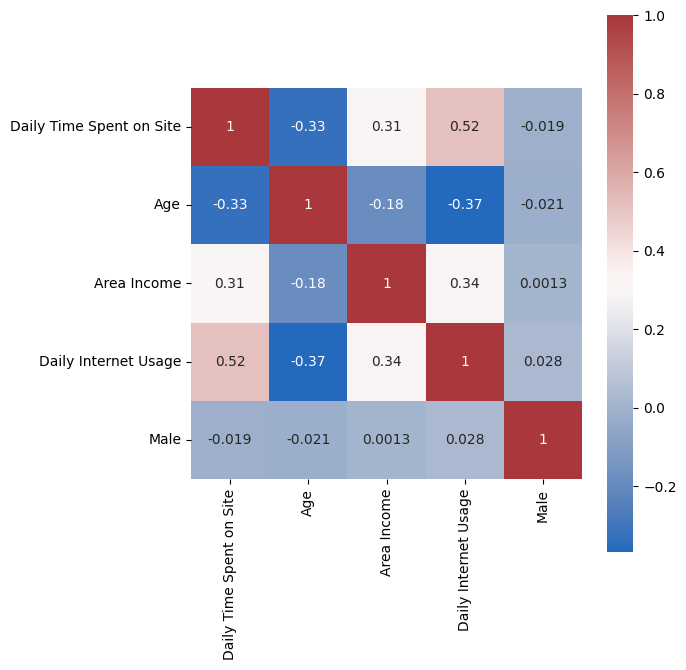

In [12]:
# Matriz de correlacion
import matplotlib.pyplot as plt

# --- 2. Calcular la correlación ---
# Usamos el método .corr() en el DataFrame de precios
correlation = X.corr()

print("Matriz de correlación calculada.")

# --- 3. Generar el Heatmap ---
# Configuramos el tamaño de la figura para que sea grande y legible
plt.figure(figsize=(7, 7))

# Creamos el heatmap con seaborn
sns.heatmap(
    correlation,        # La matriz de correlación
    vmax=1,             # El valor máximo de la barra de color (1 es correlación perfecta)
    square=True,        # Asegura que cada celda sea un cuadrado
    annot=True,         # Muestra los números (coeficientes de correlación) en cada celda
    cmap='vlag'         # El mapa de color (rojo-blanco-azul) que usa la guía
)

# Ajustamos el layout para que no se corten las etiquetas
plt.tight_layout()

# Mostramos el gráfico
plt.show()

In [7]:
# Split (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

print("Datos divididos en entrenamiento (70%) y prueba (30%) correctamente.")

Datos divididos en entrenamiento (70%) y prueba (30%) correctamente.


In [8]:
from sklearn.preprocessing import StandardScaler

# Escalar (CRÍTICO para SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datos de entrenamiento y prueba escalados correctamente para SVM.")

Datos de entrenamiento y prueba escalados correctamente para SVM.


In [22]:
from sklearn.svm import SVC # Support Vector Classifier

# Modelo 1: Kernel Lineal
svm_linear = SVC(kernel='linear')
svm_linear.fit(X_train_scaled, y_train)

# Modelo 2: Kernel RBF (Por defecto)
svm_rbf = SVC(kernel='rbf')
svm_rbf.fit(X_train_scaled, y_train)

# Modelo 3: Kernel Polinómico (tarea)
svm_poly = SVC(kernel='poly', degree=3)
svm_poly.fit(X_train_scaled, y_train)

print("Modelos SVM entrenados.")

Modelos SVM entrenados.


In [23]:
from sklearn.metrics import classification_report

pred_linear = svm_linear.predict(X_test_scaled)
pred_rbf = svm_rbf.predict(X_test_scaled)
pred_poly = svm_poly.predict(X_test_scaled)

print("--- SVM Lineal ---")
print(classification_report(y_test, pred_linear))

print("\n--- SVM RBF ---")
print(classification_report(y_test, pred_rbf))

print("\n--- SVM Poly ---")
print(classification_report(y_test, pred_poly))



--- SVM Lineal ---
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       157
           1       0.98      0.97      0.97       143

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300


--- SVM RBF ---
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       157
           1       0.98      0.94      0.96       143

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0.96      0.96      0.96       300


--- SVM Poly ---
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       157
           1       0.98      0.94      0.96       143

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0

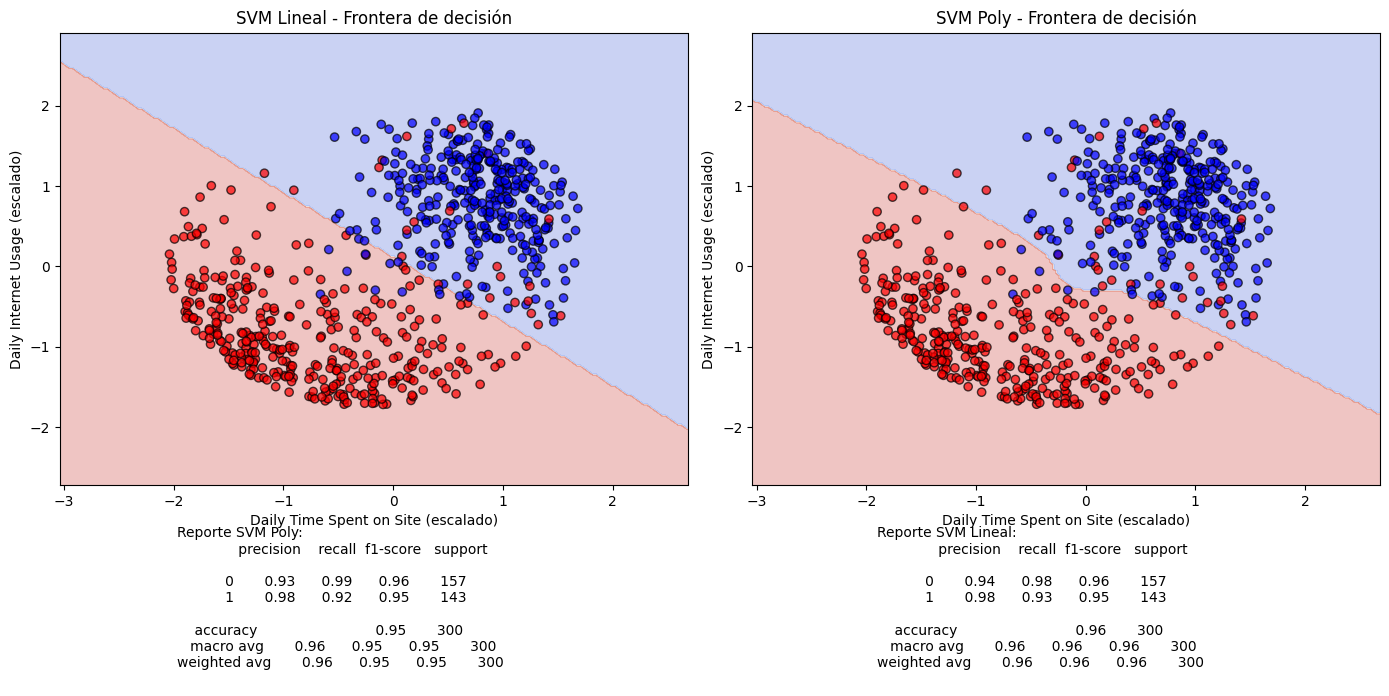

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Selecciona solo las dos variables
X2_train = X_train[['Daily Time Spent on Site', 'Daily Internet Usage']] #tarea: age, area income
X2_test = X_test[['Daily Time Spent on Site', 'Daily Internet Usage']] #tarea: age, area income

# Escala solo esas dos variables
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

svm_linear_2d = SVC(kernel='linear')
svm_linear_2d.fit(X2_train_scaled, y_train)

svm_rbf_2d = SVC(kernel='rbf')
svm_rbf_2d.fit(X2_train_scaled, y_train)

svm_poly_2d = SVC(kernel='poly', degree=3) #tarea
svm_poly_2d.fit(X2_train_scaled, y_train)


# Predicciones para el test con solo dos variables
pred_linear_2d = svm_linear_2d.predict(X2_test_scaled)
pred_rbf_2d = svm_rbf_2d.predict(X2_test_scaled)
pred_poly_2d = svm_poly_2d.predict(X2_test_scaled) #tarea

# Crear malla para graficar la frontera
x_min, x_max = X2_train_scaled[:, 0].min()-1, X2_train_scaled[:, 0].max()+1
y_min, y_max = X2_train_scaled[:, 1].min()-1, X2_train_scaled[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

# Predicciones para la malla
Z_linear = svm_linear_2d.predict(grid).reshape(xx.shape)
Z_rbf = svm_rbf_2d.predict(grid).reshape(xx.shape)
Z_poly = svm_poly_2d.predict(grid).reshape(xx.shape) #tarea

plt.figure(figsize=(14,7))

# Frontera SVM Lineal
plt.subplot(1,2,1)
plt.contourf(xx, yy, Z_linear, alpha=0.3, cmap='coolwarm')
plt.scatter(X2_train_scaled[:,0], X2_train_scaled[:,1], c=y_train, cmap='bwr', edgecolor='k', alpha=0.7)
plt.title('SVM Lineal - Frontera de decisión')
plt.xlabel('Daily Time Spent on Site (escalado)')
plt.ylabel('Daily Internet Usage (escalado)')

# Frontera SVM RBF
#plt.subplot(1,2,2)
#plt.contourf(xx, yy, Z_rbf, alpha=0.3, cmap='coolwarm')
#plt.scatter(X2_train_scaled[:,0], X2_train_scaled[:,1], c=y_train, cmap='bwr', edgecolor='k', alpha=0.7)
#plt.title('SVM RBF - Frontera de decisión')
#plt.xlabel('Daily Time Spent on Site (escalado)')
#plt.ylabel('Daily Internet Usage (escalado)')

# Frontera SVM RBF
plt.subplot(1,2,2)
plt.contourf(xx, yy, Z_poly, alpha=0.3, cmap='coolwarm')
plt.scatter(X2_train_scaled[:,0], X2_train_scaled[:,1], c=y_train, cmap='bwr', edgecolor='k', alpha=0.7)
plt.title('SVM Poly - Frontera de decisión')
plt.xlabel('Daily Time Spent on Site (escalado)')
plt.ylabel('Daily Internet Usage (escalado)')



plt.tight_layout()
plt.subplots_adjust(bottom=0.3)  # Deja más espacio abajo

# Reportes debajo de los gráficos
#plt.figtext(
#    0.13, 0.02,
#    "Reporte SVM Lineal:\n" + classification_report(y_test, pred_linear_2d),
#    wrap=True, ha='left', fontsize=10
#)
plt.figtext(
    0.63, 0.02,
    "Reporte SVM Lineal:\n" + classification_report(y_test, pred_linear_2d),
    wrap=True, ha='left', fontsize=10
)
plt.figtext(
    0.13, 0.02,
    "Reporte SVM Poly:\n" + classification_report(y_test, pred_poly_2d),
    wrap=True, ha='left', fontsize=10
)

plt.show()